In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn statsmodels joblib

In [2]:
# --- core data handling ---
import numpy as np
import pandas as pd

# --- plotting ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- machine learning ---
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             root_mean_squared_error, r2_score)

# --- statistics + model saving ---
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
import joblib

import warnings
warnings.filterwarnings("ignore")

# Make every chart look the same and every run reproducible
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

RANDOM_STATE = 42          # one seed used everywhere, so your numbers match mine
np.random.seed(RANDOM_STATE)

print("Libraries loaded.")

Libraries loaded.


In [3]:
CSV_PATH = "House_Price_Prediction_Dataset_50000.csv"

df_raw = pd.read_csv(CSV_PATH)

print(f"Rows   : {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")
df_raw.head(10)

Rows   : 50,000
Columns: 11


,House_ID,City,Property_Type,Bedrooms,Bathrooms,Area_sqft,Age_of_Property_Years,Distance_from_City_Center_km,Parking,Furnishing,Price_Lakhs
0,1,Chennai,Independent House,3,5,2528,0,36.9,1,Unfurnished,93.24
1,2,Hyderabad,Independent House,4,2,1527,3,31.5,0,Fully Furnished,176.35
2,3,Delhi,Villa,5,3,3508,29,2.9,0,Semi-Furnished,232.09
3,4,Delhi,Builder Floor,2,5,2746,23,39.0,0,Semi-Furnished,344.23
4,5,Delhi,Apartment,3,2,3001,9,28.2,0,Unfurnished,356.18
5,6,Hyderabad,Independent House,6,5,1829,12,30.8,1,Fully Furnished,195.97
6,7,Bangalore,Villa,6,2,2121,2,31.3,0,Unfurnished,387.62
7,8,Chennai,Apartment,4,3,822,26,29.4,0,Unfurnished,426.65
8,9,Chennai,Villa,3,4,2746,22,24.9,0,Semi-Furnished,469.36
9,10,Pune,Builder Floor,4,4,2844,19,12.4,0,Semi-Furnished,421.01


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   House_ID                      50000 non-null  int64  
 1   City                          50000 non-null  str    
 2   Property_Type                 50000 non-null  str    
 3   Bedrooms                      50000 non-null  int64  
 4   Bathrooms                     50000 non-null  int64  
 5   Area_sqft                     50000 non-null  int64  
 6   Age_of_Property_Years         50000 non-null  int64  
 7   Distance_from_City_Center_km  50000 non-null  float64
 8   Parking                       50000 non-null  int64  
 9   Furnishing                    50000 non-null  str    
 10  Price_Lakhs                   50000 non-null  float64
dtypes: float64(2), int64(6), str(3)
memory usage: 4.2 MB


In [6]:
# How many distinct values does each column take?
# A handful of uniques = categorical. Thousands = continuous.
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "example_values": [list(df_raw[c].dropna().unique()[:4]) for c in df_raw.columns],
})
overview

,dtype,n_unique,example_values
House_ID,int64,50000,"[1, 2, 3, 4]"
City,str,7,"[Chennai, Hyderabad, Delhi, Bangalore]"
Property_Type,str,4,"[Independent House, Villa, Builder Floor, Apar..."
Bedrooms,int64,6,"[3, 4, 5, 2]"
Bathrooms,int64,5,"[5, 2, 3, 4]"
Area_sqft,int64,3601,"[2528, 1527, 3508, 2746]"
Age_of_Property_Years,int64,31,"[0, 3, 29, 23]"
Distance_from_City_Center_km,float64,396,"[36.9, 31.5, 2.9, 39.0]"
Parking,int64,2,"[1, 0]"
Furnishing,str,3,"[Unfurnished, Fully Furnished, Semi-Furnished]"


In [7]:
df = df_raw.drop(columns=["House_ID"]).copy()

# Text columns arrive as pandas' newer string dtype. Converting them to plain object
# keeps scikit-learn and seaborn happy across library versions.
CAT_COLS = ["City", "Property_Type", "Furnishing"]
NUM_COLS = ["Bedrooms", "Bathrooms", "Area_sqft",
            "Age_of_Property_Years", "Distance_from_City_Center_km", "Parking"]
TARGET   = "Price_Lakhs"

df[CAT_COLS] = df[CAT_COLS].astype(object)

print("Numeric features    :", NUM_COLS)
print("Categorical features:", CAT_COLS)
print("Target              :", TARGET)
print("\nShape after dropping the ID:", df.shape)

Numeric features    : ['Bedrooms', 'Bathrooms', 'Area_sqft', 'Age_of_Property_Years', 'Distance_from_City_Center_km', 'Parking']
Categorical features: ['City', 'Property_Type', 'Furnishing']
Target              : Price_Lakhs

Shape after dropping the ID: (50000, 10)


In [8]:
n_dupes = int(df.duplicated().sum())
print(f"Exact duplicate rows: {n_dupes}")

if n_dupes > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Removed. New shape: {df.shape}")
else:
    print("Nothing to remove.")

Exact duplicate rows: 0
Nothing to remove.


In [9]:
def missing_report(frame):
    # Tidy table of missing values per column, biggest offender first.
    n_missing = frame.isnull().sum()
    pct = (n_missing / len(frame) * 100).round(2)
    rep = pd.DataFrame({"missing_count": n_missing, "missing_pct": pct})
    return rep[rep.missing_count > 0].sort_values("missing_count", ascending=False)


report = missing_report(df)

if report.empty:
    print("No missing values in the original file. Every single cell is filled.")
else:
    display(report)

No missing values in the original file. Every single cell is filled.


In [10]:
# ---- TEACHING STEP: inject missing values so we have something real to impute ----
rng = np.random.default_rng(RANDOM_STATE)

MISSING_PLAN = {
    "Area_sqft":             0.04,
    "Age_of_Property_Years": 0.03,
    "Furnishing":            0.03,
}

for col, frac in MISSING_PLAN.items():
    n_hits = int(len(df) * frac)
    hit_idx = rng.choice(df.index, size=n_hits, replace=False)
    df.loc[hit_idx, col] = np.nan
    print(f"Blanked {n_hits:,} values ({frac:.0%}) in '{col}'")

print("\nMissing-value report after injection:")
missing_report(df)

Blanked 2,000 values (4%) in 'Area_sqft'
Blanked 1,500 values (3%) in 'Age_of_Property_Years'
Blanked 1,500 values (3%) in 'Furnishing'

Missing-value report after injection:


,missing_count,missing_pct
Area_sqft,2000,4.0
Age_of_Property_Years,1500,3.0
Furnishing,1500,3.0


In [13]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   House_ID                      50000 non-null  int64  
 1   City                          50000 non-null  str    
 2   Property_Type                 50000 non-null  str    
 3   Bedrooms                      50000 non-null  int64  
 4   Bathrooms                     50000 non-null  int64  
 5   Area_sqft                     50000 non-null  int64  
 6   Age_of_Property_Years         50000 non-null  int64  
 7   Distance_from_City_Center_km  50000 non-null  float64
 8   Parking                       50000 non-null  int64  
 9   Furnishing                    50000 non-null  str    
 10  Price_Lakhs                   50000 non-null  float64
dtypes: float64(2), int64(6), str(3)
memory usage: 4.2 MB


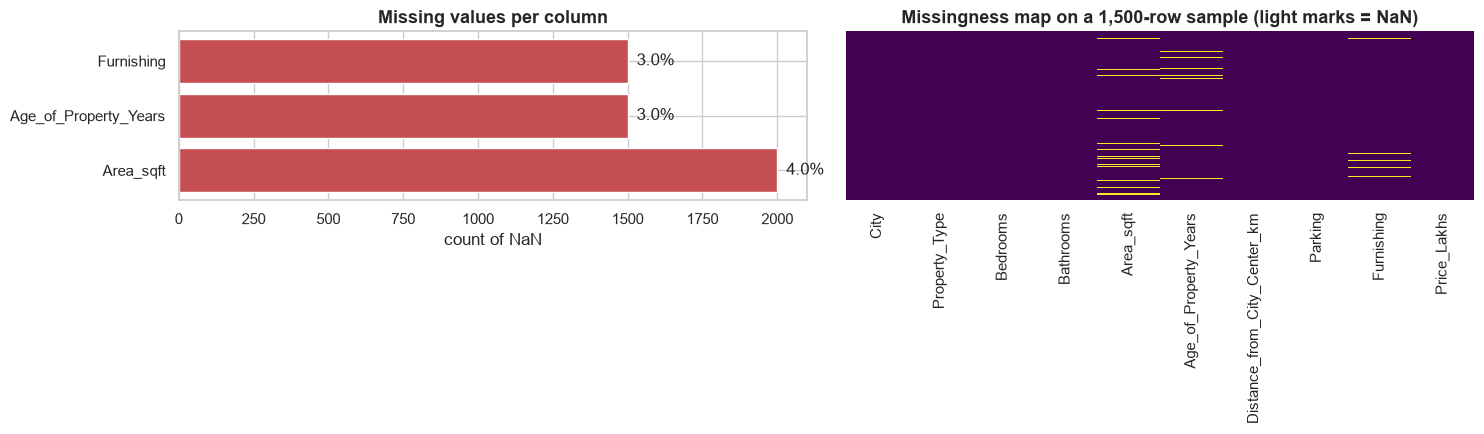

In [14]:
# Two ways to SEE missingness. Use whichever reads more clearly to you.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

rep = missing_report(df)
axes[0].barh(rep.index, rep.missing_count, color="#c44e52")
axes[0].set_title("Missing values per column")
axes[0].set_xlabel("count of NaN")
for i, (_, row) in enumerate(rep.iterrows()):
    axes[0].text(row.missing_count + 30, i, f"{row.missing_pct}%", va="center")

sns.heatmap(df.sample(1500, random_state=RANDOM_STATE).isnull(),
            cbar=False, cmap="viridis", yticklabels=False, ax=axes[1])
axes[1].set_title("Missingness map on a 1,500-row sample (light marks = NaN)")

plt.tight_layout()
plt.show()

In [15]:
# --- DEMO ONLY: see exactly what the imputer does ---
demo = df[["Area_sqft", "Age_of_Property_Years", "Furnishing"]].copy()

holes = demo[demo.Area_sqft.isnull()].head(5)      # rows that really have a hole
print("BEFORE -- five rows with a missing Area_sqft:")
display(holes)

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

filled = demo.copy()
filled[["Area_sqft", "Age_of_Property_Years"]] = num_imputer.fit_transform(
    demo[["Area_sqft", "Age_of_Property_Years"]])
filled[["Furnishing"]] = cat_imputer.fit_transform(demo[["Furnishing"]])

print("\nAFTER -- the same five rows, holes filled:")
display(filled.loc[holes.index])

print("\nWhich value did each imputer pick?")
print(f"  Area_sqft             -> median {num_imputer.statistics_[0]:,.1f}")
print(f"  Age_of_Property_Years -> median {num_imputer.statistics_[1]:,.1f}")
print(f"  Furnishing            -> mode   '{cat_imputer.statistics_[0]}'")

BEFORE -- five rows with a missing Area_sqft:


,Area_sqft,Age_of_Property_Years,Furnishing
59,NaN,16.0,Semi-Furnished
74,NaN,11.0,Unfurnished
79,NaN,27.0,Unfurnished
80,NaN,27.0,Fully Furnished
110,NaN,18.0,Fully Furnished



AFTER -- the same five rows, holes filled:


,Area_sqft,Age_of_Property_Years,Furnishing
59,2205.0,16.0,Semi-Furnished
74,2205.0,11.0,Unfurnished
79,2205.0,27.0,Unfurnished
80,2205.0,27.0,Fully Furnished
110,2205.0,18.0,Fully Furnished



Which value did each imputer pick?
  Area_sqft             -> median 2,205.0
  Age_of_Property_Years -> median 15.0
  Furnishing            -> mode   'Semi-Furnished'


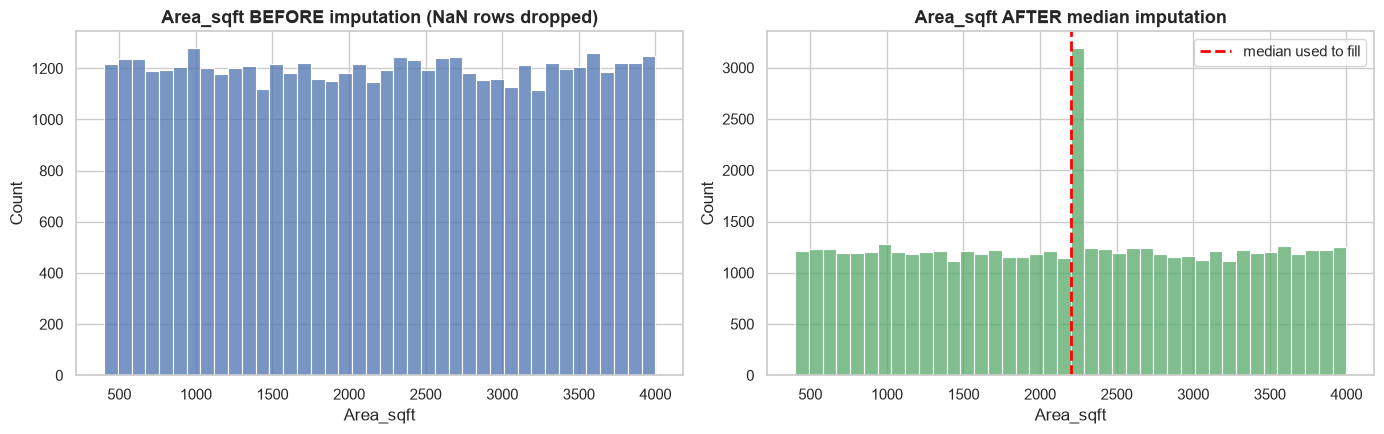

Notice the spike at the median. Filling with a single value always creates one.
That is the cost of keeping the rows. At 4% missing it is a fair trade.


In [16]:
# Imputing changes the shape of the distribution a little. You should know how much.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df["Area_sqft"].dropna(), bins=40, ax=axes[0], color="#4c72b0")
axes[0].set_title("Area_sqft BEFORE imputation (NaN rows dropped)")

sns.histplot(filled["Area_sqft"], bins=40, ax=axes[1], color="#55a868")
axes[1].axvline(num_imputer.statistics_[0], color="red", ls="--", lw=2,
                label="median used to fill")
axes[1].set_title("Area_sqft AFTER median imputation")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Notice the spike at the median. Filling with a single value always creates one.")
print("That is the cost of keeping the rows. At 4% missing it is a fair trade.")

In [17]:
df[NUM_COLS + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Bedrooms,50000.0,3.48,1.71,1.00,2.00,3.00,5.00,6.00
Bathrooms,50000.0,3.00,1.41,1.00,2.00,3.00,4.00,5.00
Area_sqft,48000.0,2198.75,1044.05,400.00,1290.00,2205.00,3107.00,4000.00
Age_of_Property_Years,48500.0,14.99,8.93,0.00,7.00,15.00,23.00,30.00
Distance_from_City_Center_km,50000.0,20.28,11.38,0.50,10.40,20.40,30.10,40.00
Parking,50000.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
Price_Lakhs,50000.0,259.28,139.07,20.01,137.46,258.68,379.73,499.99


In [18]:
# Categorical columns get a different summary: how many categories, which is most common
df[CAT_COLS].describe().T

,count,unique,top,freq
City,50000,7,Chennai,7200
Property_Type,50000,4,Independent House,12558
Furnishing,48500,3,Semi-Furnished,16240


In [19]:
# The full breakdown of every category, with percentages
for col in CAT_COLS:
    counts = df[col].value_counts(dropna=False)
    pct = (counts / len(df) * 100).round(1)
    print(f"--- {col} ---")
    print(pd.DataFrame({"count": counts, "pct": pct}).to_string())
    print()

--- City ---
           count   pct
City                  
Chennai     7200  14.4
Noida       7181  14.4
Mumbai      7175  14.4
Pune        7165  14.3
Hyderabad   7152  14.3
Delhi       7094  14.2
Bangalore   7033  14.1

--- Property_Type ---
                   count   pct
Property_Type                 
Independent House  12558  25.1
Apartment          12493  25.0
Villa              12485  25.0
Builder Floor      12464  24.9

--- Furnishing ---
                 count   pct
Furnishing                  
Semi-Furnished   16240  32.5
Unfurnished      16162  32.3
Fully Furnished  16098  32.2
NaN               1500   3.0



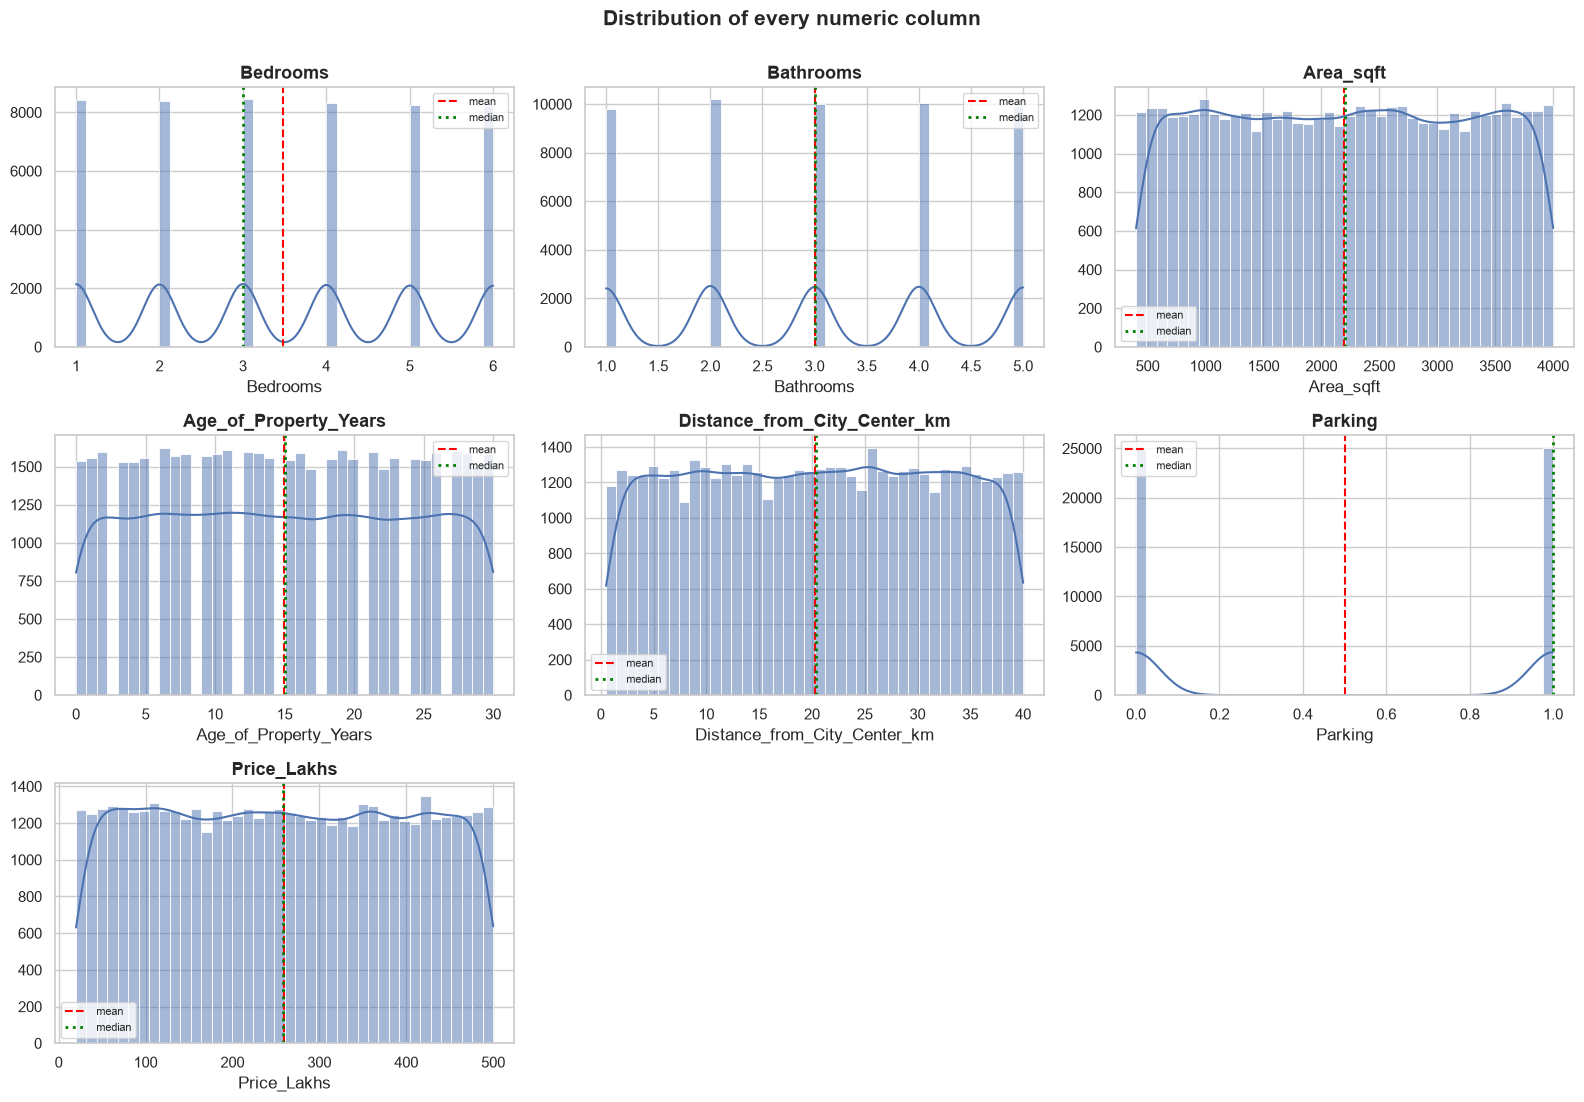

In [20]:
cols_to_plot = NUM_COLS + [TARGET]
fig, axes = plt.subplots(3, 3, figsize=(16, 11))

for ax, col in zip(axes.ravel(), cols_to_plot):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax, color="#4c72b0")
    ax.axvline(df[col].mean(), color="red", ls="--", lw=1.5, label="mean")
    ax.axvline(df[col].median(), color="green", ls=":", lw=2, label="median")
    ax.set_title(col)
    ax.set_ylabel("")
    ax.legend(fontsize=8)

for ax in axes.ravel()[len(cols_to_plot):]:
    ax.axis("off")

plt.suptitle("Distribution of every numeric column", y=1.00, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Skewness -- putting a number on the lopsidedness

Skewness measures how lopsided a distribution is.

| Skew value | Meaning |
|---|---|
| between -0.5 and +0.5 | roughly symmetric, nothing to worry about |
| -1 to -0.5 or +0.5 to +1 | moderately skewed |
| beyond -1 or +1 | strongly skewed -- consider a log transform |

Linear regression does not require the features to be normal, but a wildly skewed target often
predicts better after a log transform.

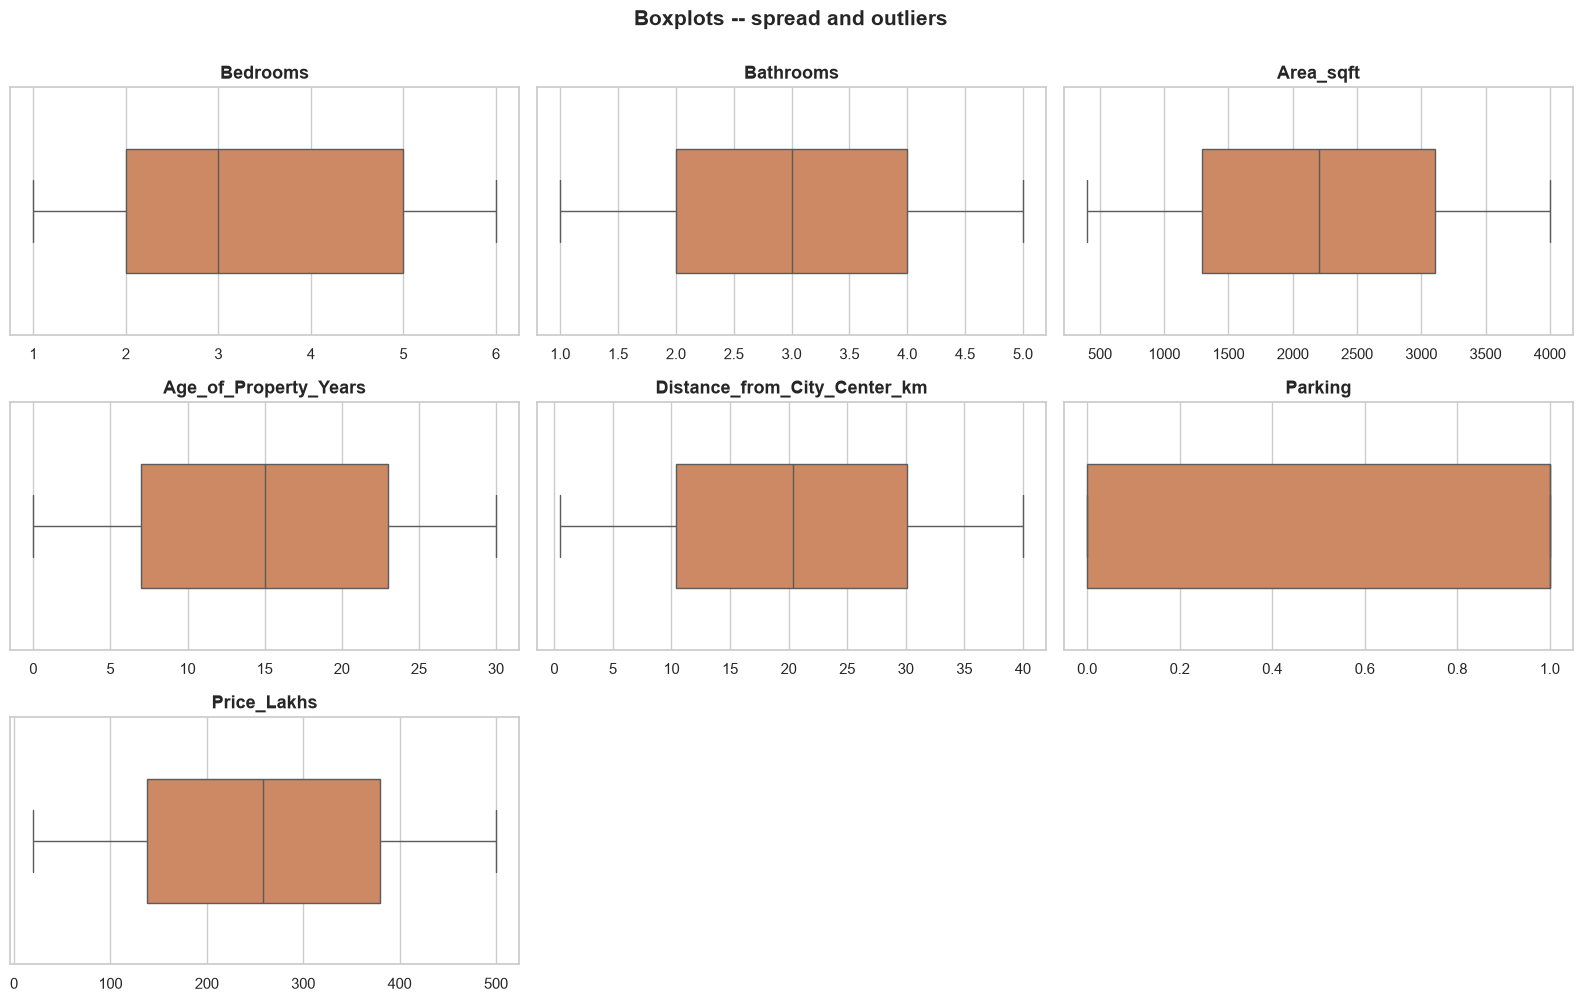

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10))

for ax, col in zip(axes.ravel(), cols_to_plot):
    sns.boxplot(x=df[col], ax=ax, color="#dd8452", width=0.5)
    ax.set_title(col)
    ax.set_xlabel("")

for ax in axes.ravel()[len(cols_to_plot):]:
    ax.axis("off")

plt.suptitle("Boxplots -- spread and outliers", y=1.00, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

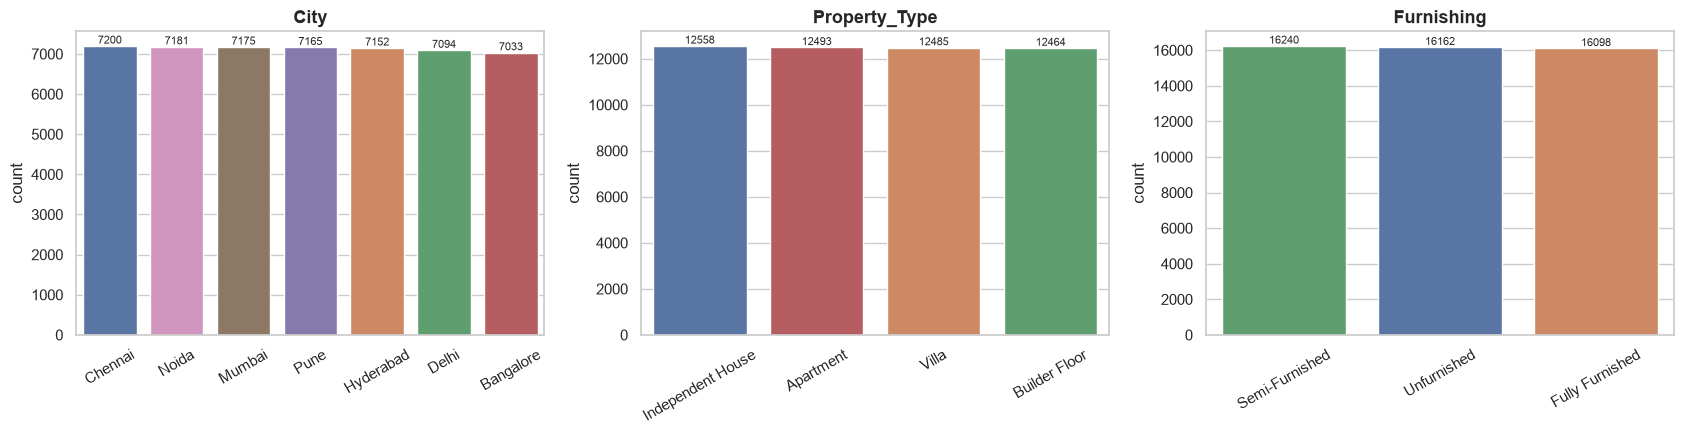

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, col in zip(axes, CAT_COLS):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, hue=col, legend=False)
    ax.set_title(f"{col}")
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("")
    for container in ax.containers:
        ax.bar_label(container, fmt="%d", fontsize=8)

plt.tight_layout()
plt.show()

In [24]:
def iqr_outliers(series):
    # Flag values outside Q1 - 1.5*IQR and Q3 + 1.5*IQR.
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < low) | (series > high)
    return low, high, int(mask.sum())


rows = []
for col in NUM_COLS + [TARGET]:
    low, high, n = iqr_outliers(df[col].dropna())
    rows.append({"column": col,
                 "lower_fence": round(low, 2),
                 "upper_fence": round(high, 2),
                 "n_outliers": n,
                 "pct_outliers": round(n / df[col].notna().sum() * 100, 2)})

pd.DataFrame(rows).set_index("column")

,lower_fence,upper_fence,n_outliers,pct_outliers
column,,,,
Bedrooms,-2.50,9.50,0,0.0
Bathrooms,-1.00,7.00,0,0.0
Area_sqft,-1435.50,5832.50,0,0.0
Age_of_Property_Years,-17.00,47.00,0,0.0
Distance_from_City_Center_km,-19.15,59.65,0,0.0
Parking,-1.50,2.50,0,0.0
Price_Lakhs,-225.93,743.12,0,0.0


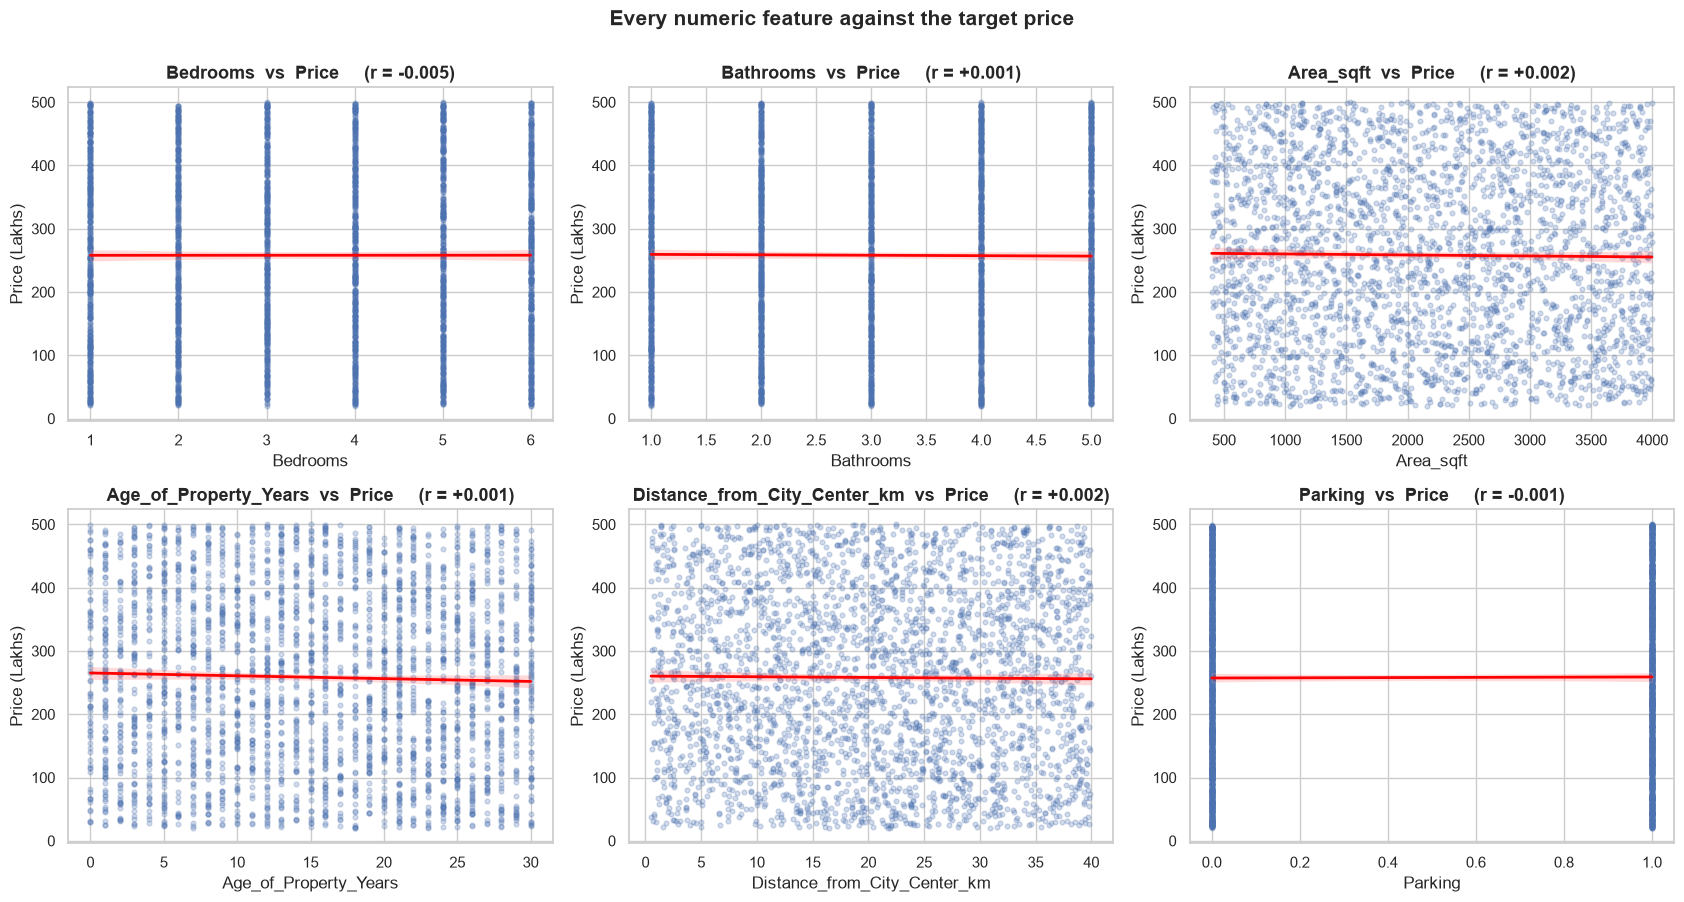

In [25]:
sample = df.sample(3000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.regplot(data=sample, x=col, y=TARGET, ax=ax,
                scatter_kws={"alpha": 0.25, "s": 12, "color": "#4c72b0"},
                line_kws={"color": "red", "lw": 2})
    r = df[[col, TARGET]].corr().iloc[0, 1]
    ax.set_title(f"{col}  vs  Price     (r = {r:+.3f})")
    ax.set_ylabel("Price (Lakhs)")

plt.suptitle("Every numeric feature against the target price",
             y=1.00, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

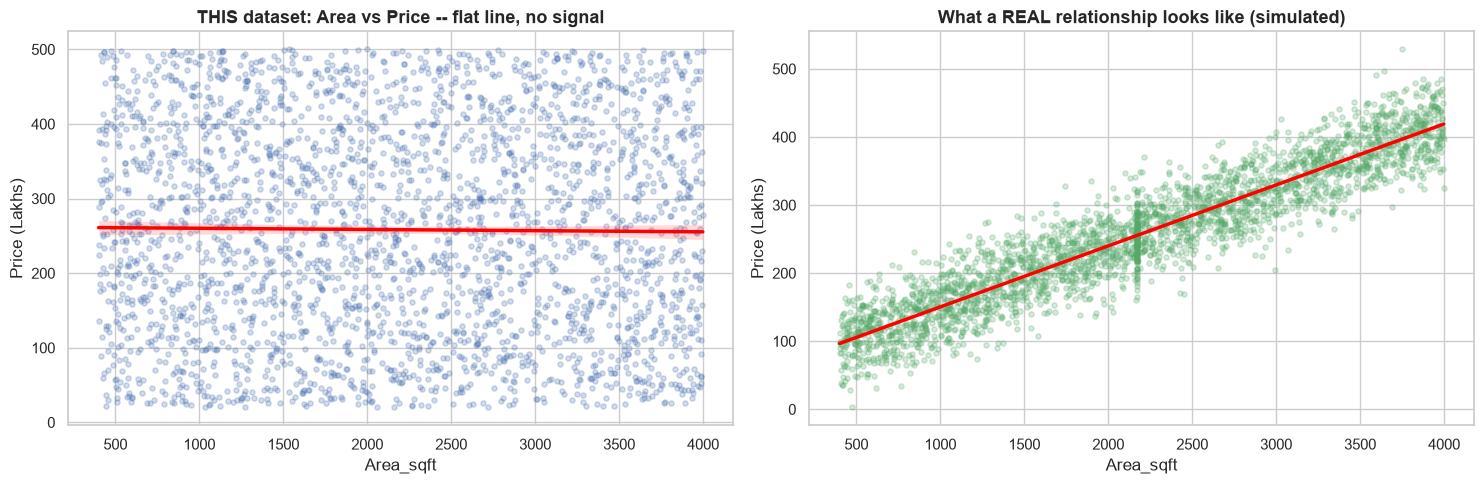

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.regplot(data=sample, x="Area_sqft", y=TARGET, ax=axes[0],
            scatter_kws={"alpha": 0.25, "s": 14, "color": "#4c72b0"},
            line_kws={"color": "red", "lw": 2.5})
axes[0].set_title("THIS dataset: Area vs Price -- flat line, no signal")
axes[0].set_ylabel("Price (Lakhs)")

# a made-up comparison so you know what a real relationship looks like
_demo_area = sample["Area_sqft"].fillna(sample["Area_sqft"].median())
_demo_price = 60 + 0.09 * _demo_area + np.random.default_rng(1).normal(0, 35, len(sample))
sns.regplot(x=_demo_area, y=_demo_price, ax=axes[1],
            scatter_kws={"alpha": 0.25, "s": 14, "color": "#55a868"},
            line_kws={"color": "red", "lw": 2.5})
axes[1].set_title("What a REAL relationship looks like (simulated)")
axes[1].set_xlabel("Area_sqft")
axes[1].set_ylabel("Price (Lakhs)")

plt.tight_layout()
plt.show()

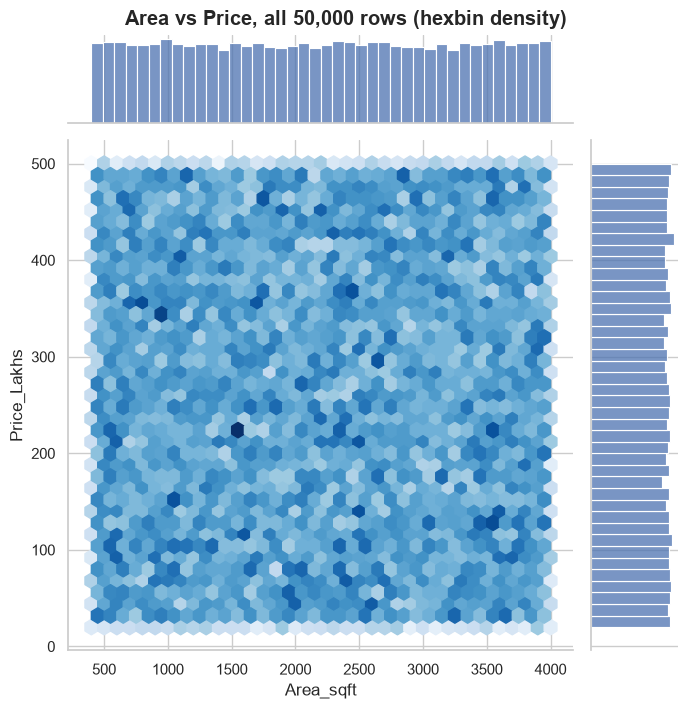

In [27]:
# With 50,000 points, a hexbin plot beats a scatter: colour = how many houses fall in each cell.
# If there were a relationship you would see a bright diagonal band. You will see a flat rectangle.
g = sns.jointplot(data=df, x="Area_sqft", y=TARGET, kind="hex",
                  height=7, cmap="Blues", marginal_kws={"bins": 40})
g.figure.suptitle("Area vs Price, all 50,000 rows (hexbin density)", y=1.01, fontweight="bold")
plt.show()

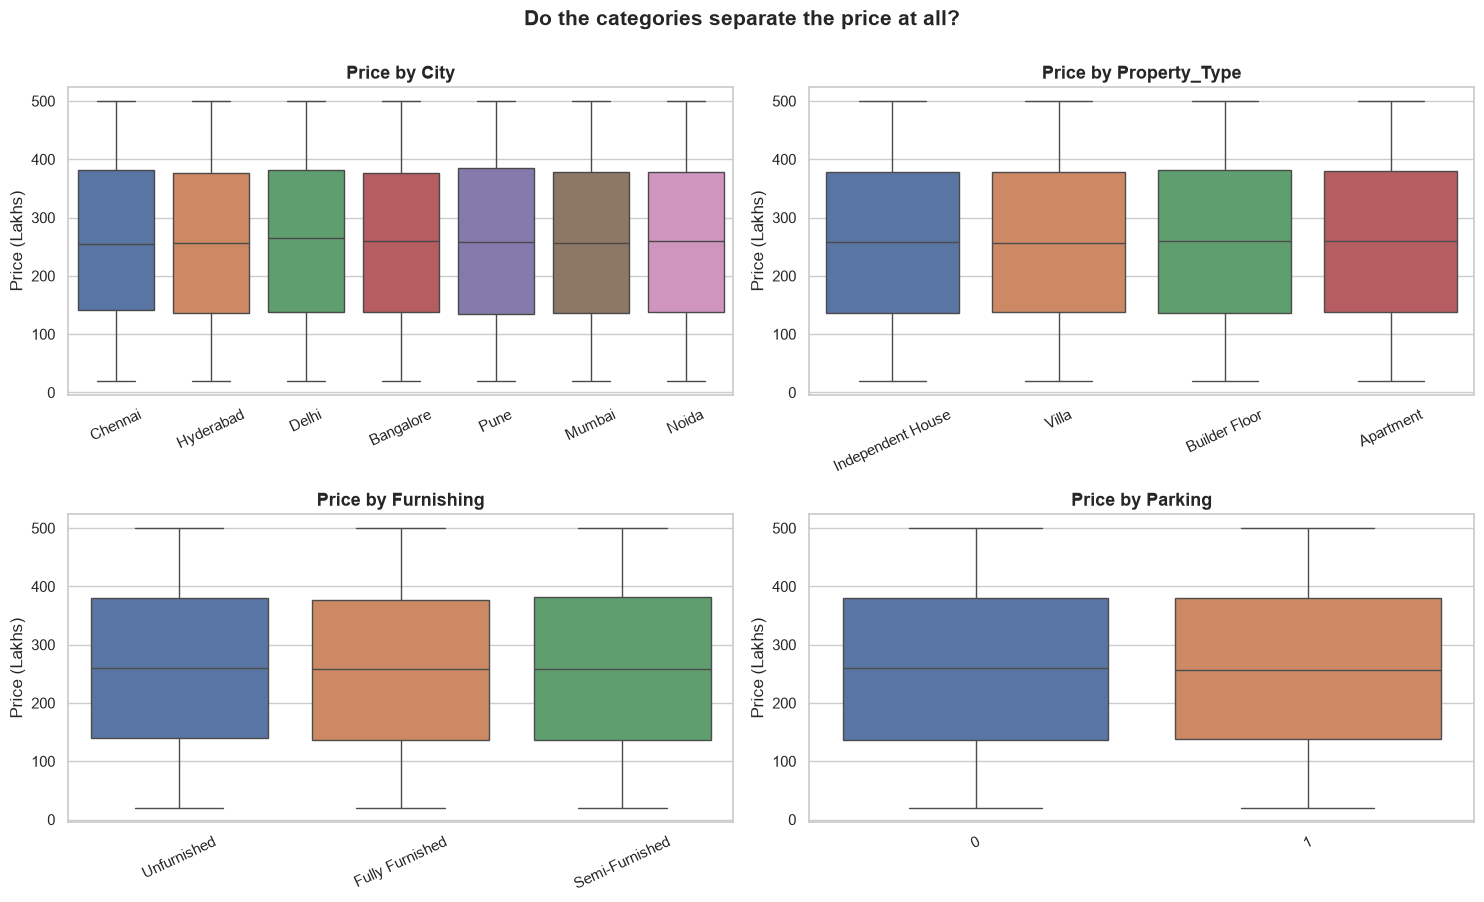

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, col in zip(axes.ravel(), CAT_COLS + ["Parking"]):
    sns.boxplot(data=df, x=col, y=TARGET, ax=ax, hue=col, legend=False)
    ax.tick_params(axis="x", rotation=25)
    ax.set_title(f"Price by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Price (Lakhs)")

plt.suptitle("Do the categories separate the price at all?",
             y=1.00, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [29]:
# The same thing as numbers: group means, and the spread between the best and worst category
for col in CAT_COLS + ["Parking"]:
    g = df.groupby(col, dropna=False)[TARGET].agg(["count", "mean", "median", "std"]).round(2)
    spread = g["mean"].max() - g["mean"].min()
    print(f"--- {col} --- (gap between highest and lowest group mean: {spread:.2f} lakhs)")
    print(g.to_string())
    print()

--- City --- (gap between highest and lowest group mean: 5.06 lakhs)
           count    mean  median     std
City                                    
Bangalore   7033  258.98  259.62  137.96
Chennai     7200  259.79  255.11  138.78
Delhi       7094  262.00  264.30  139.83
Hyderabad   7152  256.94  255.69  139.06
Mumbai      7175  257.94  257.17  138.65
Noida       7181  259.95  260.49  138.68
Pune        7165  259.39  257.99  140.55

--- Property_Type --- (gap between highest and lowest group mean: 1.68 lakhs)
                   count    mean  median     std
Property_Type                                   
Apartment          12493  259.61  259.47  138.62
Builder Floor      12464  260.06  259.90  140.27
Independent House  12558  258.38  258.29  138.39
Villa              12485  259.09  257.18  139.02

--- Furnishing --- (gap between highest and lowest group mean: 3.90 lakhs)
                 count    mean  median     std
Furnishing                                    
Fully Furnished  16

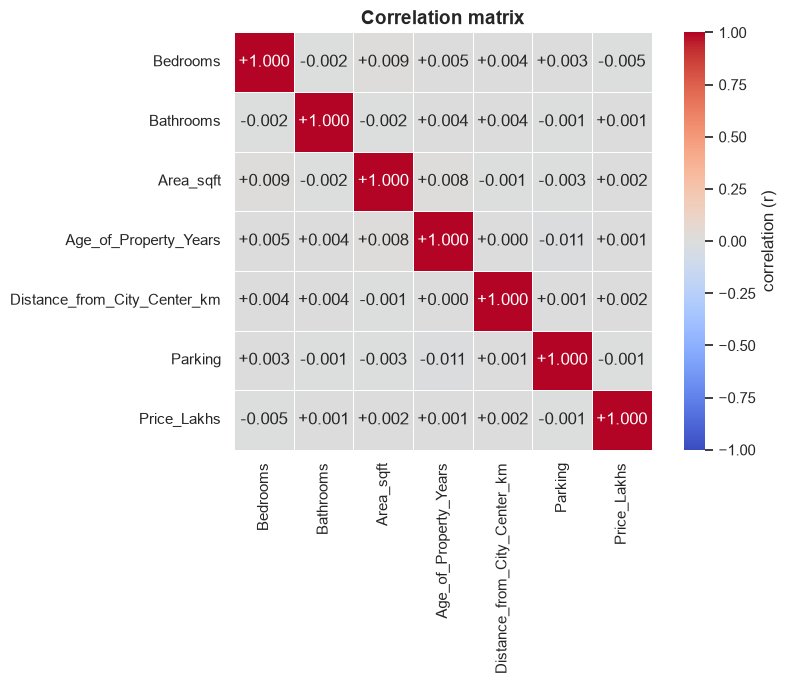

In [30]:
corr = df[NUM_COLS + [TARGET]].corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt="+.3f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "correlation (r)"})
plt.title("Correlation matrix", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

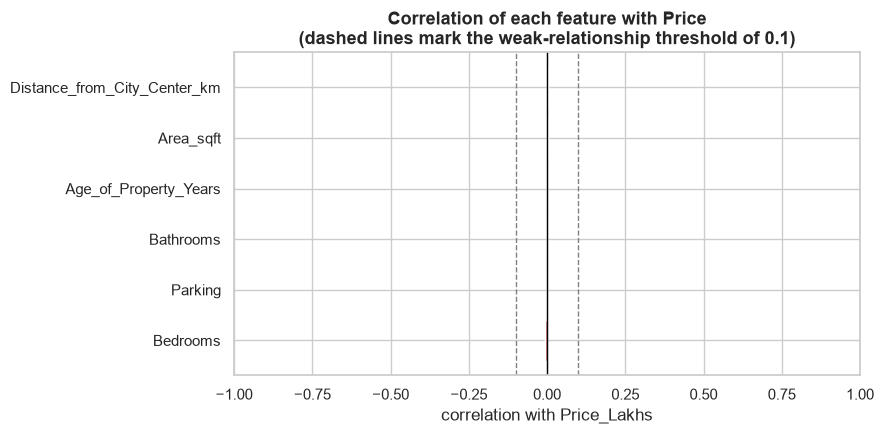

Bedrooms                       -0.0055
Parking                        -0.0011
Bathrooms                       0.0007
Age_of_Property_Years           0.0009
Area_sqft                       0.0023
Distance_from_City_Center_km    0.0023

Strongest absolute correlation with price: 0.0055


In [31]:
target_corr = corr[TARGET].drop(TARGET).sort_values()

plt.figure(figsize=(9, 4.5))
colors = ["#c44e52" if v < 0 else "#4c72b0" for v in target_corr]
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.axvline(0, color="black", lw=1)
plt.axvline(0.10, color="gray", ls="--", lw=1)
plt.axvline(-0.10, color="gray", ls="--", lw=1)
plt.xlim(-1, 1)
plt.title("Correlation of each feature with Price\n(dashed lines mark the weak-relationship threshold of 0.1)")
plt.xlabel("correlation with Price_Lakhs")
plt.tight_layout()
plt.show()

print(target_corr.round(4).to_string())
print(f"\nStrongest absolute correlation with price: {target_corr.abs().max():.4f}")

In [32]:
# A small demo so you can see the transformation on real rows
demo_rows = df[CAT_COLS].dropna().head(6)
print("BEFORE -- text categories:")
display(demo_rows)

enc_demo = OneHotEncoder(sparse_output=False, drop=None)
encoded = enc_demo.fit_transform(demo_rows)
encoded_df = pd.DataFrame(encoded.astype(int),
                          columns=enc_demo.get_feature_names_out(CAT_COLS),
                          index=demo_rows.index)

print(f"\nAFTER -- {demo_rows.shape[1]} text columns became {encoded_df.shape[1]} numeric 0/1 columns:")
display(encoded_df)

BEFORE -- text categories:


,City,Property_Type,Furnishing
0,Chennai,Independent House,Unfurnished
1,Hyderabad,Independent House,Fully Furnished
2,Delhi,Villa,Semi-Furnished
3,Delhi,Builder Floor,Semi-Furnished
4,Delhi,Apartment,Unfurnished
5,Hyderabad,Independent House,Fully Furnished



AFTER -- 3 text columns became 10 numeric 0/1 columns:


,City_Chennai,City_Delhi,City_Hyderabad,Property_Type_Apartment,Property_Type_Builder Floor,Property_Type_Independent House,Property_Type_Villa,Furnishing_Fully Furnished,Furnishing_Semi-Furnished,Furnishing_Unfurnished
0,1,0,0,0,0,1,0,0,0,1
1,0,0,1,0,0,1,0,1,0,0
2,0,1,0,0,0,0,1,0,1,0
3,0,1,0,0,1,0,0,0,1,0
4,0,1,0,1,0,0,0,0,0,1
5,0,0,1,0,0,1,0,1,0,0


In [33]:
enc_check = OneHotEncoder(sparse_output=False, drop="first")
enc_check.fit(df[CAT_COLS].fillna("MISSING"))

print("Baseline (dropped) category per column:")
for col, cats in zip(CAT_COLS, enc_check.categories_):
    print(f"  {col:<15} baseline = '{cats[0]}'   -> {len(cats) - 1} dummy columns")

print(f"\nEncoded categorical columns : {len(enc_check.get_feature_names_out(CAT_COLS))}")
print(f"Numeric columns             : {len(NUM_COLS)}")
print(f"Total features for the model: {len(enc_check.get_feature_names_out(CAT_COLS)) + len(NUM_COLS)}")

Baseline (dropped) category per column:
  City            baseline = 'Bangalore'   -> 6 dummy columns
  Property_Type   baseline = 'Apartment'   -> 3 dummy columns
  Furnishing      baseline = 'Fully Furnished'   -> 3 dummy columns

Encoded categorical columns : 12
Numeric columns             : 6
Total features for the model: 18
